# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
import importlib.metadata as metadata
import subprocess
import sys

required_versions = {
    "numpy": "2.3.5", "pandas": "2.2.3", "scipy": "1.17.0",
    "scikit-learn": "1.8.0", "matplotlib": "3.10.8", "seaborn": "0.13.2",
    "imbalanced-learn": "0.14.2", "streamlit": "1.67.0", "joblib": "1.5.3",
    "threadpoolctl": "3.6.0",
}
missing = []
for package, expected_version in required_versions.items():
    try:
        if metadata.version(package) != expected_version:
            missing.append(f"{package}=={expected_version}")
    except metadata.PackageNotFoundError:
        missing.append(f"{package}=={expected_version}")
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("Python:", sys.version.split()[0])
print("Зависимости установлены; фиксированные версии приведены в requirements-notebook.txt.")


Python: 3.12.14
Зависимости установлены; фиксированные версии приведены в requirements-notebook.txt.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
_thread_limit = threadpool_limits(limits=1)
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 20)
%matplotlib inline


No event loop hook running.


## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
from sklearn.utils import ClassifierTags


class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def __sklearn_tags__(self):


        tags = super().__sklearn_tags__()
        tags.estimator_type = 'classifier'
        tags.classifier_tags = ClassifierTags()
        tags.target_tags.required = True
        return tags

    def fit(self, X, y):
        feature_names = getattr(X, 'columns', None)
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0:
            raise ValueError('X must be a nonempty two-dimensional array.')
        if y.ndim != 1 or y.shape[0] != X.shape[0]:
            raise ValueError('y must be a vector with one label per row of X.')
        if not np.isfinite(X).all() or not np.isfinite(y).all():
            raise ValueError('X and y must contain finite values.')
        if not np.isin(y, [0, 1]).all():
            raise ValueError('Only binary labels 0 and 1 are supported.')
        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError("gd_type must be 'full' or 'stochastic'.")
        if not isinstance(self.max_iter, (int, np.integer)) or self.max_iter < 1:
            raise ValueError('max_iter must be a positive integer.')
        if not isinstance(self.batch_size, (int, np.integer)) or self.batch_size < 1:
            raise ValueError('batch_size must be a positive integer.')
        if not np.isfinite(self.eta) or self.eta <= 0:
            raise ValueError('eta must be finite and positive.')
        if not np.isfinite(self.tolerance) or self.tolerance < 0:
            raise ValueError('tolerance must be finite and nonnegative.')

        self.n_features_in_ = X.shape[1]
        if feature_names is not None:
            self.feature_names_in_ = np.asarray(feature_names, dtype=object)
        X_bias = np.column_stack((np.ones(X.shape[0]), X))
        self.w = (np.zeros(X_bias.shape[1]) if self.w0 is None
                  else np.asarray(self.w0, dtype=float).copy())
        if self.w.shape != (X_bias.shape[1],) or not np.isfinite(self.w).all():
            raise ValueError('w0 must be finite and have shape (n_features + 1,).')

        self.stop_reason_ = 'max_iter'
        for iteration in range(self.max_iter):


            self.loss_history.append(self.calc_loss(X_bias, y))

            if self.gd_type == 'full':
                gradient = self.calc_gradient(X_bias, y)
            else:
                idx = rng.choice(X_bias.shape[0],
                                 size=min(self.batch_size, X_bias.shape[0]),
                                 replace=False)
                gradient = self.calc_gradient(X_bias[idx], y[idx])

            step = self.eta * gradient
            self.w = self.w - step
            self.step_norm_ = float(np.linalg.norm(step))
            self.n_iter_ = iteration + 1
            if self.step_norm_ < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break


        self.final_loss_ = self.calc_loss(X_bias, y)
        self.intercept_ = self.w[:1].copy()
        self.coef_ = self.w[1:].reshape(1, -1).copy()
        return self

    def sigmoid(self, z):
        z = np.asarray(z, dtype=float)

        return np.exp(-np.logaddexp(0.0, -z))

    def predict_proba(self, X):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.w.size - 1:
            raise ValueError('X must have the same number of features as during fit.')
        if not np.isfinite(X).all():
            raise ValueError('X must contain finite values.')
        X_bias = np.column_stack((np.ones(X.shape[0]), X))
        p = self.sigmoid(X_bias @ self.w)
        return np.column_stack((1.0 - p, p))

    def predict(self, X, threshold=0.5):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        if not np.isfinite(threshold) or not 0 <= threshold <= 1:
            raise ValueError('threshold must lie in [0, 1].')
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        return X.T @ (self.sigmoid(X @ self.w) - y) / X.shape[0]

    def calc_loss(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        z = X @ self.w


        return float(np.mean(np.logaddexp(0.0, z) - y * z))


Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'


max |analytic - numeric| = 3.27e-11


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)


### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

,iterations,stop_reason,last_step_norm,final_train_log_loss
method,,,,
Мой GD,1000,max_iter,0.000399,0.512435
Мой SGD,1000,max_iter,0.003895,0.512909


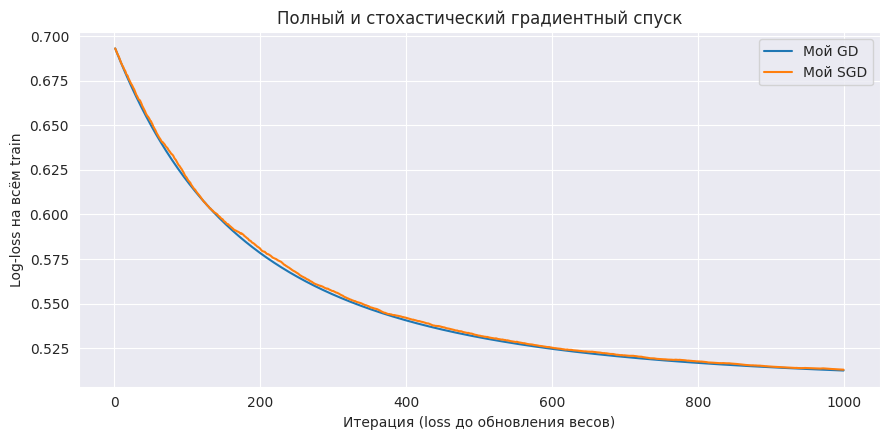

In [6]:
from IPython.display import display

gd_model = LogReg(gd_type='full').fit(X_train, y_train)
sgd_model = LogReg(gd_type='stochastic').fit(X_train, y_train)
synthetic_models = {'Мой GD': gd_model, 'Мой SGD': sgd_model}

convergence_report = pd.DataFrame([
    {'method': name, 'iterations': model.n_iter_,
     'stop_reason': model.stop_reason_, 'last_step_norm': model.step_norm_,
     'final_train_log_loss': model.final_loss_}
    for name, model in synthetic_models.items()
]).set_index('method')
display(convergence_report)

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, model in synthetic_models.items():
    ax.plot(np.arange(1, len(model.loss_history) + 1),
            model.loss_history, label=name)
ax.set(xlabel='Итерация (loss до обновления весов)', ylabel='Log-loss на всём train',
       title='Полный и стохастический градиентный спуск')
ax.legend()
plt.tight_layout()
plt.show()


**Выводы.** Обе модели с настройками по умолчанию остановились по `max_iter`: сделано по **1000 обновлений**. Нормы последних шагов GD и SGD равны примерно **0.000399** и **0.003895**, то есть больше `tolerance=0.0001`.

Полный GD уменьшает loss плавно, поскольку каждый раз использует один и тот же полный градиент. У SGD кривая более шумная: разные батчи дают разные направления, и при постоянном шаге веса продолжают колебаться около решения. Поэтому маленькая норма одного стохастического шага — ненадёжное свидетельство сходимости.

Для **оценки градиента** GD использует **14 000 объектов**, SGD — **32**. Но по условию `loss_history` считается на **всех 14 000 объектах при каждой итерации обоих методов**: поэтому данная учебная реализация SGD не получает полного обычного выигрыша по стоимости шага.

В истории первая точка — loss при исходных нулевых весах, до первого обновления. В таблице `final_train_log_loss` приведён loss уже после последнего обновления.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

,iterations,stop_reason,final_train_log_loss
eta,,,
0.001,1000,max_iter,0.618087
0.010,1000,max_iter,0.512435
0.100,465,tolerance,0.505762
1.000,70,tolerance,0.505757
10.000,1000,max_iter,0.901345


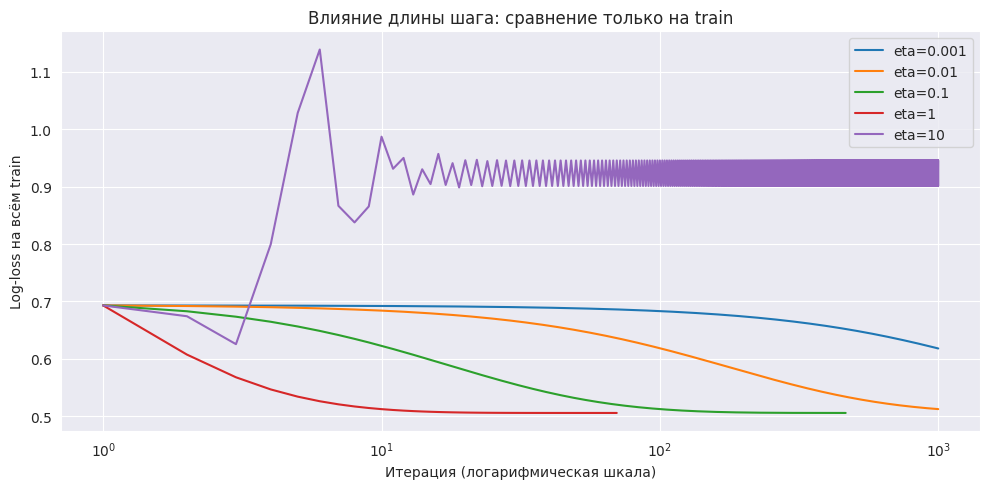

In [7]:
eta_values = [1e-3, 1e-2, 1e-1, 1, 10]
eta_models = {}
eta_rows = []
fig, ax = plt.subplots(figsize=(10, 5))

for eta in eta_values:
    model = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)
    eta_models[eta] = model
    eta_rows.append({'eta': eta, 'iterations': model.n_iter_,
                     'stop_reason': model.stop_reason_,
                     'final_train_log_loss': model.final_loss_})
    ax.plot(np.arange(1, len(model.loss_history) + 1), model.loss_history,
            label=f'eta={eta:g}')

eta_report = pd.DataFrame(eta_rows).set_index('eta')
display(eta_report)
ax.set_xscale('log')
ax.set(xlabel='Итерация (логарифмическая шкала)', ylabel='Log-loss на всём train',
       title='Влияние длины шага: сравнение только на train')
ax.legend()
plt.tight_layout()
plt.show()


**Выводы.** При `eta=0.001` спуск за 1000 итераций уменьшил loss только до **0.618087**, при `eta=0.01` — до **0.512435**. Маленький шаг даёт медленную сходимость.

На этих тренировочных данных `eta=0.1` и `eta=1` устойчиво сходятся к одному значению около **0.505757**: остановка по `tolerance` достигнута за **465** и **70** итераций соответственно. При `eta=10` спуск перескакивает через область минимума, loss колеблется, и после 1000 итераций остаётся высоким: **0.901345**.

Таким образом, увеличение шага помогает только до определённого предела. Эти выводы и сравнение шагов сделаны исключительно на train; тест для выбора `eta` не использовался. Значения в таблице измерены после последнего обновления весов.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sklearn_default = LogisticRegression(random_state=RANDOM_STATE).fit(X_train, y_train)
synthetic_models['sklearn, по умолчанию'] = sklearn_default


synthetic_comparison = pd.DataFrame([
    {'model': name,
     'accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
     'ROC_AUC': metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])}
    for name, model in synthetic_models.items()
]).set_index('model')
display(synthetic_comparison)


gd_converged = LogReg(gd_type='full', eta=0.1, max_iter=20000,
                     tolerance=1e-9).fit(X_train, y_train)
import warnings


with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Setting penalty=None will ignore the C and l1_ratio parameters', category=UserWarning)
    sklearn_unregularized = LogisticRegression(
        C=np.inf, solver='lbfgs', max_iter=10000, tol=1e-10,
        random_state=RANDOM_STATE
    ).fit(X_train, y_train)

w_sklearn = np.r_[sklearn_default.intercept_, sklearn_default.coef_.ravel()]
w_sklearn_unreg = np.r_[sklearn_unregularized.intercept_,
                        sklearn_unregularized.coef_.ravel()]
coefficient_comparison = pd.DataFrame({
    'GD_default': gd_model.w,
    'sklearn_default_L2': w_sklearn,
    'GD_converged_no_penalty': gd_converged.w,
    'sklearn_no_penalty': w_sklearn_unreg,
}, index=['intercept'] + [f'x{j}' for j in range(1, X_train.shape[1] + 1)])
display(coefficient_comparison)
print('L2-разность весов: GD default vs sklearn default =',
      np.linalg.norm(gd_model.w - w_sklearn))
print('L2-разность весов для одной задачи без регуляризации =',
      np.linalg.norm(gd_converged.w - w_sklearn_unreg))
print('GD без регуляризации: iterations =', gd_converged.n_iter_,
      '; train loss =', gd_converged.final_loss_)


L2-разность весов: GD default vs sklearn default = 0.35678325060907734
L2-разность весов для одной задачи без регуляризации = 1.060732626654126e-07
GD без регуляризации: iterations = 1734 ; train loss = 0.5057566215085435


,accuracy,ROC_AUC
model,,
Мой GD,0.7820,0.838787
Мой SGD,0.7825,0.838115
"sklearn, по умолчанию",0.7765,0.838676


,GD_default,sklearn_default_L2,GD_converged_no_penalty,sklearn_no_penalty
intercept,-0.002114,-0.021880,-0.022163,-0.022163
x1,0.006076,0.002741,0.002762,0.002762
x2,0.006963,0.009039,0.008962,0.008962
x3,-0.547170,-0.722690,-0.723248,-0.723248
x4,-0.144536,-0.262335,-0.262776,-0.262776
x5,0.012487,0.016588,0.016537,0.016537
x6,-0.006325,-0.011488,-0.011549,-0.011549
x7,0.000814,0.005587,0.005580,0.005580
x8,0.039084,0.057188,0.057240,0.057240
x9,-0.002425,-0.001239,-0.001201,-0.001201


**Выводы.** Метрики близки, но не совпадают: accuracy GD — **0.7820**, SGD — **0.7825**, sklearn — **0.7765**; ROC-AUC у всех находится около **0.838**. Разница между небольшими значениями test-метрик не используется для подбора параметров.

Веса при настройках по умолчанию не совпадают: L2-норма разности весов GD и sklearn около **0.3568**. Причины две: наш GD за 1000 итераций ещё не сошёлся, а sklearn по умолчанию добавляет **L2-регуляризацию** (`C=1`). В нашем классе штрафа на веса нет. Также реализации используют разные оптимизаторы и критерии остановки.

Для одной задачи без регуляризации в установленном sklearn **1.8.0** задаём `C=np.inf`, оставляем свободный член, повышаем `max_iter` и уменьшаем `tol`. В версиях до перехода на новый интерфейс эквивалентный вариант — `penalty=None` с совместимым solver. См. [официальную документацию LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

Дополнительная проверка **только на train**: при точной сходимости GD и sklearn без регуляризации норма разности весов составляет примерно **1.06 × 10⁻⁷**, train loss — **0.50575662**. Это подтверждает правильность градиента и реализации; точное совпадение весов вообще не гарантировано при линейно зависимых признаках, но предсказания в одной задаче должны совпадать с учётом точности оптимизации.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
from pathlib import Path
from zipfile import ZipFile
from IPython.display import display


data_path = Path('Data/wine_quality.csv')
if data_path.exists():
    df_raw = pd.read_csv(data_path)
else:
    archive_candidates = [Path('Data.zip'), Path('upload/Data.zip'), Path('../upload/Data.zip')]
    archive_path = next((p for p in archive_candidates if p.exists()), None)
    if archive_path is None:
        raise FileNotFoundError('Положите Data.zip или папку Data рядом с ноутбуком.')
    with ZipFile(archive_path) as archive:
        with archive.open('Data/wine_quality.csv') as source:
            df_raw = pd.read_csv(source)

raw_missing = int(df_raw.isna().sum().sum())
raw_duplicates = int(df_raw.duplicated().sum())

df = df_raw.drop_duplicates().reset_index(drop=True)
assert df.isna().sum().sum() == 0
assert set(df['target'].unique()) == {0, 1}
answers = globals().get('answers', {})

print('Исходные данные:', df_raw.shape)
print('Пропущенных значений:', raw_missing)
print('Полных дубликатов:', raw_duplicates)
print('После удаления точных повторов:', df.shape)
display(df.head())


Исходные данные: (6497, 13)
Пропущенных значений: 0
Полных дубликатов: 1177
После удаления точных повторов: (5320, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)


assert X_train.merge(X_test, on=list(X.columns), how='inner').empty
print('Train:', X_train.shape, 'Test:', X_test.shape)


Train: (3724, 12) Test: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
prevalence_train = float(y_train.mean())
prevalence_test = float(y_test.mean())
display(pd.DataFrame({
    'выборка': ['train', 'test'],
    'объектов': [len(y_train), len(y_test)],
    'класс 1': [int(y_train.sum()), int(y_test.sum())],
    'prevalence': [prevalence_train, prevalence_test],
}))

constant_predictions = np.zeros(len(y_test), dtype=int)
wine_model = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
wine_model.fit(X_train, y_train)
base_test_proba = wine_model.predict_proba(X_test)[:, 1]
base_predictions = (base_test_proba >= 0.5).astype(int)
accuracy_comparison = pd.DataFrame({
    'модель': ['Всегда класс 0', 'Логистическая регрессия'],
    'accuracy': [metrics.accuracy_score(y_test, constant_predictions),
                 metrics.accuracy_score(y_test, base_predictions)],
})
display(accuracy_comparison)
print('Итераций sklearn:', int(wine_model[-1].n_iter_[0]))

def evaluate_scores(name, probabilities, threshold=0.5, targets=None):

    targets = np.asarray(y_test if targets is None else targets)
    probabilities = np.asarray(probabilities)
    labels = (probabilities >= threshold).astype(int)
    return {
        'модель': name, 'порог': float(threshold),
        'accuracy': metrics.accuracy_score(targets, labels),
        'precision': metrics.precision_score(targets, labels, zero_division=0),
        'recall': metrics.recall_score(targets, labels, zero_division=0),
        'F1': metrics.f1_score(targets, labels, zero_division=0),
        'ROC-AUC': metrics.roc_auc_score(targets, probabilities),
        'PR-AUC': metrics.average_precision_score(targets, probabilities),
    }

def evaluate_model(name, model, threshold=0.5, X_eval=None, y_eval=None):
    X_eval = X_test if X_eval is None else X_eval
    y_eval = y_test if y_eval is None else y_eval
    return evaluate_scores(name, model.predict_proba(X_eval)[:, 1], threshold, y_eval)

answers[26] = (
    f'Пропусков нет, полных дубликатов {raw_duplicates}. Удалены только точные повторы '
    f'до разбиения: осталось {len(df)} строк. Без идентификаторов нельзя доказать, '
    'что это разные вина; такой выбор не позволяет одному и тому же составу '
    'попасть одновременно в train и test. Это решение о подготовке данных, а не '
    'подбор по тестовым метрикам.\n\n'
    f'Доля хороших вин: train — {prevalence_train:.2%}, test — {prevalence_test:.2%}. '
    '`stratify=y` сохраняет близкое соотношение классов в обеих частях. '
    f'Accuracy константной модели равна {accuracy_comparison.iloc[0]["accuracy"]:.4f}, '
    f'логистической регрессии — {accuracy_comparison.iloc[1]["accuracy"]:.4f}. '
    'Большая accuracy возможна даже при полном игнорировании хороших вин; '
    'поэтому отдельно нужны precision, recall и PR-AUC.'
)


Итераций sklearn: 20


,выборка,объектов,класс 1,prevalence
0,train,3724,706,0.189581
1,test,1596,303,0.189850


,модель,accuracy
0,Всегда класс 0,0.810150
1,Логистическая регрессия,0.815163


**Выводы:**

Пропусков нет, полных дубликатов 1177. Удалены только точные повторы до разбиения: осталось 5320 строк. Без идентификаторов нельзя доказать, что это разные вина; такой выбор не позволяет одному и тому же составу попасть одновременно в train и test. Это решение о подготовке данных, а не подбор по тестовым метрикам.

Доля хороших вин: train — 18.96%, test — 18.98%. `stratify=y` сохраняет близкое соотношение классов в обеих частях. Accuracy константной модели равна 0.8102, логистической регрессии — 0.8152. Большая accuracy возможна даже при полном игнорировании хороших вин; поэтому отдельно нужны precision, recall и PR-AUC.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TN=1209, FP=84, FN=211, TP=92
Матрицы совпали: True


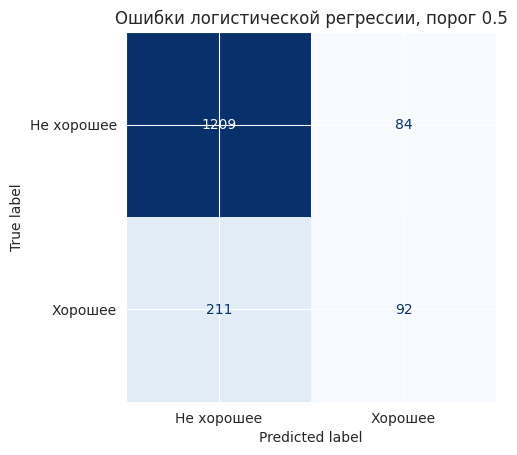

In [12]:
truth = np.asarray(y_test, dtype=int)
predicted = np.asarray(base_predictions, dtype=int)
TP = int(np.sum((truth == 1) & (predicted == 1)))
TN = int(np.sum((truth == 0) & (predicted == 0)))
FP = int(np.sum((truth == 0) & (predicted == 1)))
FN = int(np.sum((truth == 1) & (predicted == 0)))
manual_cm = np.array([[TN, FP], [FN, TP]])
sklearn_cm = metrics.confusion_matrix(truth, predicted, labels=[0, 1])
assert np.array_equal(manual_cm, sklearn_cm)
print(f'TN={TN}, FP={FP}, FN={FN}, TP={TP}')
print('Матрицы совпали:', np.array_equal(manual_cm, sklearn_cm))
metrics.ConfusionMatrixDisplay(
    manual_cm, display_labels=['Не хорошее', 'Хорошее']).plot(cmap='Blues', colorbar=False)
plt.title('Ошибки логистической регрессии, порог 0.5')
plt.show()
answers[29] = (
    f'FP={FP}: посредственное вино попало в рекомендации. '
    f'FN={FN}: хорошее вино не попало в подборку. '
    f'Чаще встречается ошибка {"FN" if FN > FP else "FP" if FP > FN else "обоих типов поровну"}. '
    'На пороге 0.5 модель осторожно выдаёт положительный класс и пропускает '
    'заметную часть хороших вин. Матрица, посчитанная вручную, совпала со sklearn.'
)


**Выводы:**

FP=84: посредственное вино попало в рекомендации. FN=211: хорошее вино не попало в подборку. Чаще встречается ошибка FN. На пороге 0.5 модель осторожно выдаёт положительный класс и пропускает заметную часть хороших вин. Матрица, посчитанная вручную, совпала со sklearn.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision_manual = TP / (TP + FP) if TP + FP else 0.0
recall_manual = TP / (TP + FN) if TP + FN else 0.0

def fbeta_manual(precision, recall, beta):
    denominator = beta ** 2 * precision + recall
    return (1 + beta ** 2) * precision * recall / denominator if denominator else 0.0

manual_values = {
    'precision': precision_manual,
    'recall': recall_manual,
    'F1': fbeta_manual(precision_manual, recall_manual, 1),
    'F0.5': fbeta_manual(precision_manual, recall_manual, 0.5),
    'F2': fbeta_manual(precision_manual, recall_manual, 2),
}
sklearn_values = {
    'precision': metrics.precision_score(truth, predicted, zero_division=0),
    'recall': metrics.recall_score(truth, predicted, zero_division=0),
    'F1': metrics.fbeta_score(truth, predicted, beta=1, zero_division=0),
    'F0.5': metrics.fbeta_score(truth, predicted, beta=0.5, zero_division=0),
    'F2': metrics.fbeta_score(truth, predicted, beta=2, zero_division=0),
}
fbeta_comparison = pd.DataFrame({'вручную': manual_values, 'sklearn': sklearn_values})
assert np.allclose(fbeta_comparison['вручную'], fbeta_comparison['sklearn'])
display(fbeta_comparison)
answers[32] = (
    f'Ручные значения совпали со sklearn: precision={precision_manual:.4f}, '
    f'recall={recall_manual:.4f}, F1={manual_values["F1"]:.4f}, '
    f'F0.5={manual_values["F0.5"]:.4f}, F2={manual_values["F2"]:.4f}.\n\n'
    'F0.5 сильнее учитывает precision, F2 — recall, F1 даёт им равный вес. '
    'Для клиентов, болезненно реагирующих на посредственные вина, выбрал бы F0.5; '
    'для максимально широкой подборки хороших вин — F2. '
    'В любом случае порог и целевую метрику задаём до финального тестирования.'
)


,вручную,sklearn
precision,0.522727,0.522727
recall,0.303630,0.303630
F1,0.384134,0.384134
F0.5,0.456802,0.456802
F2,0.331412,0.331412


**Выводы:**

Ручные значения совпали со sklearn: precision=0.5227, recall=0.3036, F1=0.3841, F0.5=0.4568, F2=0.3314.

F0.5 сильнее учитывает precision, F2 — recall, F1 даёт им равный вес. Для клиентов, болезненно реагирующих на посредственные вина, выбрал бы F0.5; для максимально широкой подборки хороших вин — F2. В любом случае порог и целевую метрику задаём до финального тестирования.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

GD: eta=1.05957, итераций=3620, норма градиента=9.398e-07


,модель,ROC-AUC,PR-AUC
0,sklearn LR,0.820876,0.484766
1,Ручной GD,0.820562,0.483764


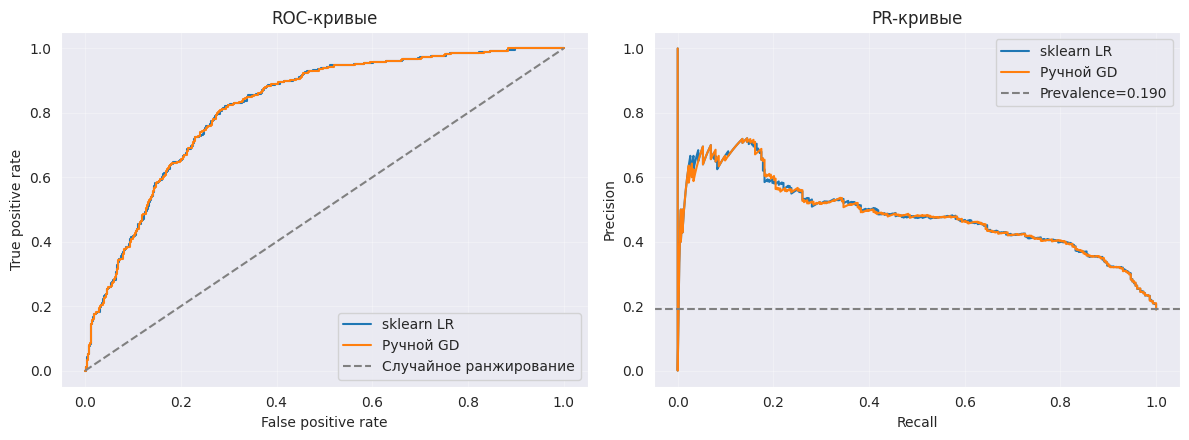

,оценки,ROC-AUC
0,p,0.820876
1,10p,0.820876
2,p³,0.820876
3,logit(p),0.820876
4,-p,0.179124
5,Метки при t=0.5,0.619333


In [14]:
wine_scaler = StandardScaler().fit(X_train)
wine_X_scaled = wine_scaler.transform(X_train)
wine_X_bias = np.column_stack([np.ones(len(X_train)), wine_X_scaled])
lipschitz_bound = np.linalg.eigvalsh(wine_X_bias.T @ wine_X_bias / (4 * len(X_train)))[-1]
wine_eta = float(1 / lipschitz_bound)
model_wine_gd = LogReg(
    gd_type='full', eta=wine_eta, tolerance=1e-6,
    max_iter=50000, random_state=RANDOM_STATE)
model_wine_gd.fit(wine_X_scaled, y_train.to_numpy())
wine_gradient_norm = float(np.linalg.norm(model_wine_gd.calc_gradient(wine_X_bias, y_train.to_numpy())))
wine_gd_iterations = len(model_wine_gd.loss_history)
print(f'GD: eta={wine_eta:.5f}, итераций={wine_gd_iterations}, '
      f'норма градиента={wine_gradient_norm:.3e}')
assert wine_gd_iterations < model_wine_gd.max_iter, 'Нужно увеличить max_iter на train'
gd_test_proba = model_wine_gd.predict_proba(wine_scaler.transform(X_test))[:, 1]

wine_roc_pr = pd.DataFrame([
    evaluate_scores('sklearn LR', base_test_proba),
    evaluate_scores('Ручной GD', gd_test_proba),
])[['модель', 'ROC-AUC', 'PR-AUC']]
display(wine_roc_pr)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, scores in [('sklearn LR', base_test_proba), ('Ручной GD', gd_test_proba)]:
    fpr, tpr, _ = metrics.roc_curve(y_test, scores)
    pr_precision, pr_recall, _ = metrics.precision_recall_curve(y_test, scores)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(pr_recall, pr_precision, label=name)
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Случайное ранжирование')
axes[1].axhline(prevalence_test, ls='--', color='gray', label=f'Prevalence={prevalence_test:.3f}')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC-кривые')
axes[1].set(xlabel='Recall', ylabel='Precision', title='PR-кривые')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

p = np.clip(base_test_proba, 1e-15, 1 - 1e-15)
transformed_scores = {
    'p': p, '10p': 10 * p, 'p³': p ** 3,
    'logit(p)': np.log(p / (1 - p)), '-p': -p,
    'Метки при t=0.5': base_predictions,
}
auc_transformations = pd.DataFrame([
    {'оценки': name, 'ROC-AUC': metrics.roc_auc_score(y_test, scores)}
    for name, scores in transformed_scores.items()
])
display(auc_transformations)
original_auc = metrics.roc_auc_score(y_test, p)
for transformed in (10 * p, p ** 3, np.log(p / (1 - p))):
    assert np.isclose(original_auc, metrics.roc_auc_score(y_test, transformed))
assert np.isclose(metrics.roc_auc_score(y_test, -p), 1 - original_auc)
roc_order = wine_roc_pr.sort_values('ROC-AUC', ascending=False)['модель'].tolist()
pr_order = wine_roc_pr.sort_values('PR-AUC', ascending=False)['модель'].tolist()
answers[35] = (
    f'По ROC-AUC лидирует {roc_order[0]}, по PR-AUC — {pr_order[0]}; '
    f'порядок моделей {"совпадает" if roc_order == pr_order else "различается"}. '
    'Разница невелика: обе модели линейные, но sklearn по умолчанию использует L2-регуляризацию. '
    f'Сходимость ручного GD проверена по train, а не по тесту: {wine_gd_iterations} итераций, '
    f'норма градиента {wine_gradient_norm:.2e}.\n\n'
    f'Базовый уровень precision и average precision случайного ранжирования — доля класса 1, '
    f'здесь примерно {prevalence_test:.4f}, а не 0.5. Для конечной случайной выборки '
    'average precision колеблется вокруг этого уровня. Метрика, названная в задании PR-AUC, '
    'вычисляется как average precision, а не трапецеидальная площадь.\n\n'
    'Преобразования 10p, p³ и logit(p) строго возрастают и не меняют порядок объектов, '
    'поэтому ROC-AUC сохраняется. -p обращает порядок: новый AUC равен 1−AUC. '
    'Метки классов дают только два уровня оценки: большинство информации о ранжировании '
    f'теряется, хотя sklearn посчитает AUC={metrics.roc_auc_score(y_test, base_predictions):.4f}; '
    'для бинарных оценок это среднее recall и specificity.'
)


**Выводы:**

По ROC-AUC лидирует sklearn LR, по PR-AUC — sklearn LR; порядок моделей совпадает. Разница невелика: обе модели линейные, но sklearn по умолчанию использует L2-регуляризацию. Сходимость ручного GD проверена по train, а не по тесту: 3620 итераций, норма градиента 9.40e-07.

Базовый уровень precision и average precision случайного ранжирования — доля класса 1, здесь примерно 0.1898, а не 0.5. Для конечной случайной выборки average precision колеблется вокруг этого уровня. Метрика, названная в задании PR-AUC, вычисляется как average precision, а не трапецеидальная площадь.

Преобразования 10p, p³ и logit(p) строго возрастают и не меняют порядок объектов, поэтому ROC-AUC сохраняется. -p обращает порядок: новый AUC равен 1−AUC. Метки классов дают только два уровня оценки: большинство информации о ранжировании теряется, хотя sklearn посчитает AUC=0.6193; для бинарных оценок это среднее recall и specificity.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

,правило,threshold,precision,recall,F1
0,Максимум F1,0.286550,0.470339,0.630682,0.538835
1,Максимум precision при recall ≥ 0.7,0.236359,0.426117,0.704545,0.531049


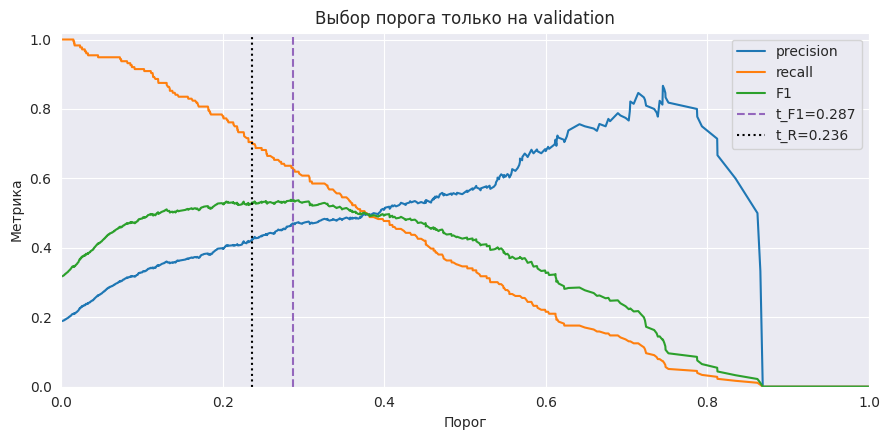

,модель,порог,precision,recall,F1
0,"LR, t=0.5",0.500000,0.522727,0.303630,0.384134
1,"LR, t_F1",0.286550,0.457421,0.620462,0.526611
2,"LR, t_R",0.236359,0.421260,0.706271,0.527744


In [15]:
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)
validation_model = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
validation_model.fit(X_subtrain, y_subtrain)
validation_proba = validation_model.predict_proba(X_val)[:, 1]

def threshold_table(targets, probabilities):

    targets = np.asarray(targets, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    thresholds = np.unique(np.r_[0.0, probabilities, 1.0])
    predictions = probabilities[:, None] >= thresholds[None, :]
    true_positives = np.sum(predictions & (targets[:, None] == 1), axis=0)
    chosen = predictions.sum(axis=0)
    precision = np.divide(true_positives, chosen, out=np.zeros(len(chosen), dtype=float), where=chosen > 0)
    recall = true_positives / np.sum(targets == 1)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros(len(chosen), dtype=float), where=(precision + recall) > 0)
    return pd.DataFrame({'threshold': thresholds, 'precision': precision, 'recall': recall, 'F1': f1})

validation_thresholds = threshold_table(y_val, validation_proba)
best_f1_row = validation_thresholds.sort_values(
    ['F1', 'precision', 'threshold'], ascending=[False, False, False]).iloc[0]
best_recall_row = validation_thresholds.loc[validation_thresholds['recall'] >= 0.7].sort_values(
    ['precision', 'recall', 'threshold'], ascending=[False, False, False]).iloc[0]
t_F1 = float(best_f1_row['threshold'])
t_R = float(best_recall_row['threshold'])
threshold_choices = pd.DataFrame([
    {'правило': 'Максимум F1', **best_f1_row.to_dict()},
    {'правило': 'Максимум precision при recall ≥ 0.7', **best_recall_row.to_dict()},
])
display(threshold_choices)

fig, ax = plt.subplots(figsize=(9, 4.5))
for name in ['precision', 'recall', 'F1']:
    ax.plot(validation_thresholds['threshold'], validation_thresholds[name], label=name)
ax.axvline(t_F1, ls='--', color='tab:purple', label=f't_F1={t_F1:.3f}')
ax.axvline(t_R, ls=':', color='black', label=f't_R={t_R:.3f}')
ax.set(xlabel='Порог', ylabel='Метрика', xlim=(0, 1), ylim=(0, 1.02), title='Выбор порога только на validation')
ax.legend()
plt.tight_layout()
plt.show()


final_selection_rule = 'unweighted_LR_with_validation_recall_constraint'
wine_model.fit(X_train, y_train)
base_test_proba = wine_model.predict_proba(X_test)[:, 1]
threshold_test_results = pd.DataFrame([
    evaluate_scores('LR, t=0.5', base_test_proba, 0.5),
    evaluate_scores('LR, t_F1', base_test_proba, t_F1),
    evaluate_scores('LR, t_R', base_test_proba, t_R),
])
display(threshold_test_results[['модель', 'порог', 'precision', 'recall', 'F1']])
test_recall_R = float(threshold_test_results.iloc[2]['recall'])
answers[38] = (
    f'На validation выбраны t_F1={t_F1:.4f} '
    f'(precision={best_f1_row["precision"]:.3f}, recall={best_f1_row["recall"]:.3f}, F1={best_f1_row["F1"]:.3f}) '
    f'и t_R={t_R:.4f} '
    f'(precision={best_recall_row["precision"]:.3f}, recall={best_recall_row["recall"]:.3f}). '
    f'На тесте при t_R recall={test_recall_R:.3f}, поэтому условие recall ≥ 0.7 '
    f'{"выполнилось" if test_recall_R >= 0.7 else "не выполнилось"}.\n\n'
    'Validation — конечная выборка, и после переобучения на всём train немного меняются '
    'веса и вероятности. Поэтому ограничение, выполненное на validation, не гарантируется '
    'на новых данных. Для указанного сервиса выбираю обычную LR с t_R: это максимум '
    'precision среди проверенных порогов при требовании найти не менее 70% хороших вин '
    'на validation. Решение зафиксировано по train/validation; тестовые числа его только оценивают. '
    'Если 70% — жёсткая производственная гарантия, нужны запас по recall и независимая '
    'проверка доверительной границы, а не подгонка по текущему тесту.'
)


**Выводы:**

На validation выбраны t_F1=0.2865 (precision=0.470, recall=0.631, F1=0.539) и t_R=0.2364 (precision=0.426, recall=0.705). На тесте при t_R recall=0.706, поэтому условие recall ≥ 0.7 выполнилось.

Validation — конечная выборка, и после переобучения на всём train немного меняются веса и вероятности. Поэтому ограничение, выполненное на validation, не гарантируется на новых данных. Для указанного сервиса выбираю обычную LR с t_R: это максимум precision среди проверенных порогов при требовании найти не менее 70% хороших вин на validation. Решение зафиксировано по train/validation; тестовые числа его только оценивают. Если 70% — жёсткая производственная гарантия, нужны запас по recall и независимая проверка доверительной границы, а не подгонка по текущему тесту.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
from sklearn.base import clone

class_models = {
    'LR без весов': make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE)),
    'LR balanced': make_pipeline(StandardScaler(), LogisticRegression(
        class_weight='balanced', random_state=RANDOM_STATE)),
}
for model in class_models.values():
    model.fit(X_train, y_train)
class_weight_results = pd.DataFrame([
    evaluate_model(name, model) for name, model in class_models.items()
])
display(class_weight_results)
class_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (2 * class_counts)
display(pd.DataFrame({'число объектов': class_counts, 'вес balanced': class_weights}))
plain_result = class_weight_results.iloc[0]
balanced_result = class_weight_results.iloc[1]
answers[42] = (
    'Для двух классов sklearn использует вес w_c = N / (2 · n_c). '
    f'Здесь класс 0 получает {class_weights.loc[0]:.4f}, класс 1 — {class_weights.loc[1]:.4f}. '
    'Общая сумма весов каждого класса становится одинаковой.\n\n'
    f'Без весов precision={plain_result["precision"]:.3f}, recall={plain_result["recall"]:.3f}; '
    f'с balanced precision={balanced_result["precision"]:.3f}, recall={balanced_result["recall"]:.3f}. '
    'Штраф за пропуск редкого класса увеличился: модель чаще относит вина к хорошим, '
    'обычно повышая recall за счёт precision и accuracy. '
    f'ROC-AUC изменился на {balanced_result["ROC-AUC"] - plain_result["ROC-AUC"]:+.4f}, '
    f'PR-AUC — на {balanced_result["PR-AUC"] - plain_result["PR-AUC"]:+.4f}: '
    'ранжирование меняется слабее, чем решение при фиксированном пороге 0.5.'
)


,модель,порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,LR без весов,0.5,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
1,LR balanced,0.5,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147


,число объектов,вес balanced
target,,
0,3018,0.616965
1,706,2.637394


**Выводы:**

Для двух классов sklearn использует вес w_c = N / (2 · n_c). Здесь класс 0 получает 0.6170, класс 1 — 2.6374. Общая сумма весов каждого класса становится одинаковой.

Без весов precision=0.523, recall=0.304; с balanced precision=0.399, recall=0.785. Штраф за пропуск редкого класса увеличился: модель чаще относит вина к хорошим, обычно повышая recall за счёт precision и accuracy. ROC-AUC изменился на +0.0001, PR-AUC — на -0.0036: ранжирование меняется слабее, чем решение при фиксированном пороге 0.5.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.pipeline import make_pipeline as make_resampling_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss-2': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE),
}
resampling_models = {}
resampled_class_sizes = []
for name, sampler in samplers.items():
    model = make_resampling_pipeline(
        StandardScaler(), clone(sampler), LogisticRegression(random_state=RANDOM_STATE))
    model.fit(X_train, y_train)
    resampling_models[name] = model

    scaled_train = model.named_steps['standardscaler'].transform(X_train)
    _, y_resampled = clone(sampler).fit_resample(scaled_train, y_train)
    counts = pd.Series(y_resampled).value_counts()
    resampled_class_sizes.append({'метод': name, 'класс 0': int(counts.get(0, 0)),
                                  'класс 1': int(counts.get(1, 0)), 'всего': len(y_resampled)})

display(pd.DataFrame(resampled_class_sizes))
resampling_results = pd.DataFrame([
    evaluate_model(name, model) for name, model in resampling_models.items()
])
imbalance_results = pd.concat([class_weight_results, resampling_results], ignore_index=True)
display(imbalance_results)


smote_raw_first = make_resampling_pipeline(
    SMOTE(random_state=RANDOM_STATE), StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE))
smote_raw_first.fit(X_train, y_train)
order_comparison = pd.DataFrame([
    evaluate_model('Scaler → SMOTE → LR', resampling_models['SMOTE']),
    evaluate_model('SMOTE → Scaler → LR', smote_raw_first),
])
display(order_comparison)
order_probability_difference = float(np.mean(np.abs(
    resampling_models['SMOTE'].predict_proba(X_test)[:, 1]
    - smote_raw_first.predict_proba(X_test)[:, 1])))
print(f'Среднее абсолютное отличие вероятностей: {order_probability_difference:.4f}')

best_sampling = resampling_results.sort_values('PR-AUC', ascending=False).iloc[0]
worst_sampling = resampling_results.sort_values('PR-AUC', ascending=True).iloc[0]
answers[45] = (
    '`imblearn`-pipeline умеет вызывать fit_resample только во время fit; '
    'обычный sklearn-pipeline требует преобразователь с transform и не подходит '
    'для такого шага. При predict/predict_proba тест проходит масштабирование '
    'и классификатор, а ресемплинг пропускается: число и состав тестовых объектов не меняются.\n\n'
    'Балансировка до train/test split создаёт утечку: копии либо связанные синтетические '
    'объекты могут оказаться по разные стороны разбиения, а тест перестаёт отражать '
    'естественную долю хороших вин. Все scaler и sampler здесь обучены только на train.\n\n'
    f'Среди четырёх способов на этом тесте лучший PR-AUC у {best_sampling["модель"]} '
    f'({best_sampling["PR-AUC"]:.4f}), худший у {worst_sampling["модель"]} '
    f'({worst_sampling["PR-AUC"]:.4f}). Это описание финальных оценок, а не выбор '
    'параметров по тесту. Случайный undersampling теряет данные большинства, NearMiss '
    'оставляет специальную приграничную часть и может искажать распределение, '
    'oversampling повторяет имеющиеся точки, SMOTE добавляет интерполяции, не обязательно '
    'соответствующие реальным винам. Признак is_red бинарный: обычный SMOTE может '
    'получать дробные значения при интерполяции между цветами. Здесь оставлен '
    'именно требуемый в задании SMOTE; в реальном проекте для такого признака '
    'нужен SMOTENC либо отдельный ресемплинг внутри каждого цвета. '
    'Лучший метод не обязан быть одинаковым на других данных.\n\n'
    'Для NearMiss и SMOTE порядок особенно важен: они используют расстояния, '
    'а единицы измерения признаков сильно различаются. RandomUnderSampler и '
    'RandomOverSampler не используют расстояния: при том же seed выбираются те же '
    'индексы. Но весь pipeline всё равно может измениться, потому что scaler после '
    'ресемплинга оценивает средние и дисперсии уже на другом распределении, а LR '
    'регуляризует коэффициенты в полученном масштабе. '
    f'В опыте со SMOTE среднее отличие вероятностей равно {order_probability_difference:.4f}, '
    f'PR-AUC: {order_comparison.iloc[0]["PR-AUC"]:.4f} против '
    f'{order_comparison.iloc[1]["PR-AUC"]:.4f}.'
)


Среднее абсолютное отличие вероятностей: 0.0166


,метод,класс 0,класс 1,всего
0,RandomUnderSampler,706,706,1412
1,NearMiss-2,706,706,1412
2,RandomOverSampler,3018,3018,6036
3,SMOTE,3018,3018,6036


,модель,порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,LR без весов,0.5,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
1,LR balanced,0.5,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
2,RandomUnderSampler,0.5,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
3,NearMiss-2,0.5,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
4,RandomOverSampler,0.5,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
5,SMOTE,0.5,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606


,модель,порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,Scaler → SMOTE → LR,0.5,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606
1,SMOTE → Scaler → LR,0.5,0.739348,0.402418,0.768977,0.528345,0.821629,0.485152


**Выводы:**

`imblearn`-pipeline умеет вызывать fit_resample только во время fit; обычный sklearn-pipeline требует преобразователь с transform и не подходит для такого шага. При predict/predict_proba тест проходит масштабирование и классификатор, а ресемплинг пропускается: число и состав тестовых объектов не меняются.

Балансировка до train/test split создаёт утечку: копии либо связанные синтетические объекты могут оказаться по разные стороны разбиения, а тест перестаёт отражать естественную долю хороших вин. Все scaler и sampler здесь обучены только на train.

Среди четырёх способов на этом тесте лучший PR-AUC у RandomOverSampler (0.4811), худший у NearMiss-2 (0.4479). Это описание финальных оценок, а не выбор параметров по тесту. Случайный undersampling теряет данные большинства, NearMiss оставляет специальную приграничную часть и может искажать распределение, oversampling повторяет имеющиеся точки, SMOTE добавляет интерполяции, не обязательно соответствующие реальным винам. Признак is_red бинарный: обычный SMOTE может получать дробные значения при интерполяции между цветами. Здесь оставлен именно требуемый в задании SMOTE; в реальном проекте для такого признака нужен SMOTENC либо отдельный ресемплинг внутри каждого цвета. Лучший метод не обязан быть одинаковым на других данных.

Для NearMiss и SMOTE порядок особенно важен: они используют расстояния, а единицы измерения признаков сильно различаются. RandomUnderSampler и RandomOverSampler не используют расстояния: при том же seed выбираются те же индексы. Но весь pipeline всё равно может измениться, потому что scaler после ресемплинга оценивает средние и дисперсии уже на другом распределении, а LR регуляризует коэффициенты в полученном масштабе. В опыте со SMOTE среднее отличие вероятностей равно 0.0166, PR-AUC: 0.4796 против 0.4852.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

,модель,порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,"LR balanced, t=0.5",0.50000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
1,"LR без весов, t_F1",0.28655,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766


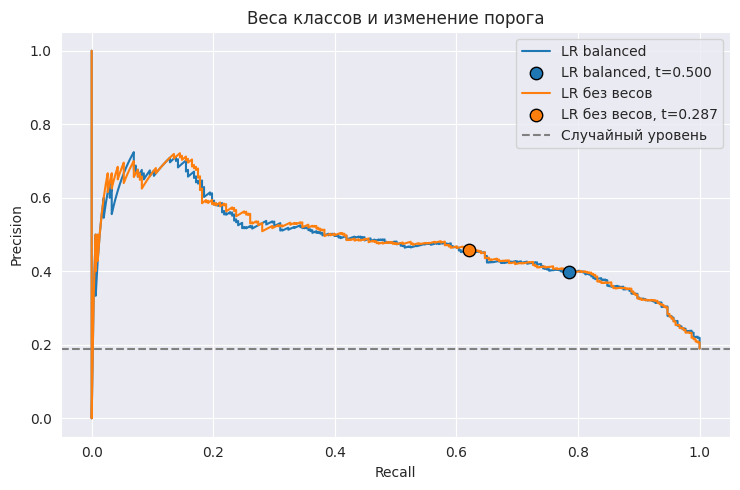

In [18]:
balanced_scores = class_models['LR balanced'].predict_proba(X_test)[:, 1]
threshold_vs_weights = pd.DataFrame([
    evaluate_scores('LR balanced, t=0.5', balanced_scores, 0.5),
    evaluate_scores('LR без весов, t_F1', base_test_proba, t_F1),
])
display(threshold_vs_weights)

fig, ax = plt.subplots(figsize=(7.5, 5))
for name, scores, threshold in [
    ('LR balanced', balanced_scores, 0.5),
    ('LR без весов', base_test_proba, t_F1),
]:
    pr_precision, pr_recall, _ = metrics.precision_recall_curve(y_test, scores)
    line, = ax.plot(pr_recall, pr_precision, label=name)
    labels = (scores >= threshold).astype(int)
    point_precision = metrics.precision_score(y_test, labels, zero_division=0)
    point_recall = metrics.recall_score(y_test, labels, zero_division=0)
    ax.scatter(point_recall, point_precision, s=80, color=line.get_color(),
               edgecolor='black', zorder=4, label=f'{name}, t={threshold:.3f}')
ax.axhline(prevalence_test, ls='--', color='gray', label='Случайный уровень')
ax.set(xlabel='Recall', ylabel='Precision', title='Веса классов и изменение порога')
ax.legend()
plt.tight_layout()
plt.show()
ap_difference = float(metrics.average_precision_score(y_test, balanced_scores)
                      - metrics.average_precision_score(y_test, base_test_proba))
answers[48] = (
    f'PR-AUC без весов — {metrics.average_precision_score(y_test, base_test_proba):.4f}, '
    f'с balanced — {metrics.average_precision_score(y_test, balanced_scores):.4f} '
    f'(разница {ap_difference:+.4f}). PR-кривые близки, но не идентичны. '
    'Изменение порога выбирает другую точку на одной и той же кривой и не меняет '
    'ранжирование. Взвешивание заново обучает и свободный член, и наклоны: '
    'в этой задаче его эффект во многом похож на снижение порога, но математически '
    'это не одно и то же. Точки на графике показывают разные компромиссы '
    'precision/recall, а не превосходство одной стратегии при любом пороге.'
)


**Выводы:**

PR-AUC без весов — 0.4848, с balanced — 0.4811 (разница -0.0036). PR-кривые близки, но не идентичны. Изменение порога выбирает другую точку на одной и той же кривой и не меняет ранжирование. Взвешивание заново обучает и свободный член, и наклоны: в этой задаче его эффект во многом похож на снижение порога, но математически это не одно и то же. Точки на графике показывают разные компромиссы precision/recall, а не превосходство одной стратегии при любом пороге.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
all_wine_models = {**class_models, **resampling_models}
all_test_rows = [evaluate_scores('Всегда класс 0', np.zeros(len(y_test)), 0.5)]
all_test_rows += [evaluate_model(name, model) for name, model in all_wine_models.items()]
all_test_rows += [
    evaluate_scores('Ручной GD', gd_test_proba, 0.5),
    evaluate_scores('LR без весов, t_F1', base_test_proba, t_F1),
    evaluate_scores('LR без весов, t_R — итог', base_test_proba, t_R),
    evaluate_model('SMOTE до scaler: контроль порядка', smote_raw_first),
]
all_results = pd.DataFrame(all_test_rows)
display(all_results)


validation_rows = []
for name, template in all_wine_models.items():
    candidate = clone(template).fit(X_subtrain, y_subtrain)
    validation_rows.append(evaluate_model(name, candidate, X_eval=X_val, y_eval=y_val))
validation_rows += [
    evaluate_scores('LR без весов, t_F1', validation_proba, t_F1, y_val),
    evaluate_scores('LR без весов, t_R — итог', validation_proba, t_R, y_val),
]
validation_model_results = pd.DataFrame(validation_rows)
print('Отдельная таблица validation (никакого выбора по тесту):')
display(validation_model_results)

final_model = wine_model
final_threshold = float(t_R)
final_test_row = evaluate_scores('Итог: LR + t_R', base_test_proba, final_threshold)
answers[51] = (
    f'Для сервиса предлагаю обычную логистическую регрессию с t_R={final_threshold:.4f}. '
    'Это правило выбрано в 2.5 по validation: максимум precision при recall ≥ 0.7. '
    f'На validation precision={best_recall_row["precision"]:.3f}, '
    f'recall={best_recall_row["recall"]:.3f}. '
    f'После обучения на всём train тестовая оценка: precision={final_test_row["precision"]:.3f}, '
    f'recall={final_test_row["recall"]:.3f}, F1={final_test_row["F1"]:.3f}, '
    f'ROC-AUC={final_test_row["ROC-AUC"]:.3f}, PR-AUC={final_test_row["PR-AUC"]:.3f}. '
    'Низкий порог делает подборку шире, но часть рекомендованных вин будет посредственной. '
    'Для премиальной узкой подборки следовало бы заранее выбрать другой критерий '
    '(например, F0.5 или минимум precision), а не менять задачу после просмотра теста.\n\n'
    'Метрики всех моделей приведены на одном неизменённом тесте; таблица нужна для '
    'финального сравнения, а не для перебора решений до желаемого тестового числа. '
    'Ресемплинг не дал оснований усложнять заранее выбранный простой pipeline. '
    'При переносе в сервис нужны проверка на новых партиях вин и мониторинг доли '
    'хороших вин: ни текущие метрики, ни коэффициенты не являются гарантией или '
    'причинным объяснением качества конкретного вина.'
)


Отдельная таблица validation (никакого выбора по тесту):


,модель,порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,Всегда класс 0,0.500000,0.810150,0.000000,0.000000,0.000000,0.500000,0.189850
1,LR без весов,0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
2,LR balanced,0.500000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
3,RandomUnderSampler,0.500000,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
4,NearMiss-2,0.500000,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
5,RandomOverSampler,0.500000,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
6,SMOTE,0.500000,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606
7,Ручной GD,0.500000,0.814536,0.520000,0.300330,0.380753,0.820562,0.483764
8,"LR без весов, t_F1",0.286550,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766
9,"LR без весов, t_R — итог",0.236359,0.760025,0.421260,0.706271,0.527744,0.820876,0.484766


,модель,порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
0,LR без весов,0.500000,0.825994,0.564815,0.346591,0.429577,0.824285,0.523514
1,LR balanced,0.500000,0.722879,0.382857,0.761364,0.509506,0.824308,0.522796
2,RandomUnderSampler,0.500000,0.725027,0.387640,0.784091,0.518797,0.825331,0.522514
3,NearMiss-2,0.500000,0.642320,0.321995,0.806818,0.460292,0.786326,0.478929
4,RandomOverSampler,0.500000,0.727175,0.387931,0.767045,0.515267,0.824262,0.529602
5,SMOTE,0.500000,0.727175,0.385965,0.750000,0.509653,0.822629,0.525680
6,"LR без весов, t_F1",0.286550,0.795918,0.470339,0.630682,0.538835,0.824285,0.523514
7,"LR без весов, t_R — итог",0.236359,0.764769,0.426117,0.704545,0.531049,0.824285,0.523514


**Выводы:**

Для сервиса предлагаю обычную логистическую регрессию с t_R=0.2364. Это правило выбрано в 2.5 по validation: максимум precision при recall ≥ 0.7. На validation precision=0.426, recall=0.705. После обучения на всём train тестовая оценка: precision=0.421, recall=0.706, F1=0.528, ROC-AUC=0.821, PR-AUC=0.485. Низкий порог делает подборку шире, но часть рекомендованных вин будет посредственной. Для премиальной узкой подборки следовало бы заранее выбрать другой критерий (например, F0.5 или минимум precision), а не менять задачу после просмотра теста.

Метрики всех моделей приведены на одном неизменённом тесте; таблица нужна для финального сравнения, а не для перебора решений до желаемого тестового числа. Ресемплинг не дал оснований усложнять заранее выбранный простой pipeline. При переносе в сервис нужны проверка на новых партиях вин и мониторинг доли хороших вин: ни текущие метрики, ни коэффициенты не являются гарантией или причинным объяснением качества конкретного вина.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib
import platform
from pathlib import Path
from importlib.metadata import version

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)


final_model = wine_model
final_threshold = float(t_R)
joblib.dump(final_model, app_dir / 'model.joblib')
config = {
    'threshold': final_threshold,
    'threshold_F1': float(t_F1),
    'threshold_R': float(t_R),
    'feature_names': X_train.columns.tolist(),
    'selection_rule': final_selection_rule,
    'model_name': 'StandardScaler + LogisticRegression, без весов',
    'target_definition': 'target=1: экспертная оценка вина не ниже 7',
    'random_state': RANDOM_STATE,
    'validation': {k: float(best_recall_row[k]) for k in ['precision', 'recall', 'F1']},
    'test_metrics': {k: float(v) for k, v in final_test_row.items() if k not in ['модель']},
    'training': {
        'raw_rows': int(len(df_raw)), 'duplicates_removed': int(raw_duplicates),
        'clean_rows': int(len(df)), 'train_rows': int(len(X_train)),
        'test_rows': int(len(X_test)), 'prevalence_train': float(prevalence_train),
    },
    'versions': {
        'python': platform.python_version(),
        'scikit-learn': version('scikit-learn'),
        'numpy': version('numpy'), 'pandas': version('pandas'), 'joblib': version('joblib'),
    },
}
(app_dir / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)
X_test.head(8).to_csv(app_dir / 'example_wines.csv', index=False)
print('Сохранены:', ', '.join(['model.joblib', 'config.json', 'test.csv', 'example_wines.csv']))
assert np.allclose(joblib.load(app_dir / 'model.joblib').predict_proba(X_test), final_model.predict_proba(X_test))


Сохранены: model.joblib, config.json, test.csv, example_wines.csv


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

https://github.com/StudentSK0/wine-quality.git

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Статус:** приложение опубликовано на Streamlit Community Cloud с Python 3.12: [Wine Quality](https://wine-quality-3gkpzaqhgfu5jtyl9vo3be.streamlit.app/). Публичный интерфейс проверен 7 ноября 2026 года без входа в аккаунт; архив `wine_app/` также подготовлен.

### Код приложения и файлы для запуска

Следующие ячейки записывают готовые файлы в `wine_app/`. Весь интерфейс заданий 4.1–4.5 реализован в `app.py`; обучение при запуске приложения не выполняется.

In [21]:
%%writefile wine_app/app.py
from __future__ import annotations

import csv
import io
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st
from sklearn import metrics


BASE_DIR = Path(__file__).resolve().parent
FEATURES = [
    "fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar",
    "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide", "density",
    "pH", "sulphates", "alcohol", "is_red",
]
LABELS = {
    "fixed_acidity": "Фиксированная кислотность",
    "volatile_acidity": "Летучая кислотность",
    "citric_acid": "Лимонная кислота",
    "residual_sugar": "Остаточный сахар",
    "chlorides": "Хлориды",
    "free_sulfur_dioxide": "Свободный диоксид серы",
    "total_sulfur_dioxide": "Общий диоксид серы",
    "density": "Плотность",
    "pH": "pH",
    "sulphates": "Сульфаты",
    "alcohol": "Алкоголь, %",
    "is_red": "Красное вино",
}
WINE = "#822f52"
TEAL = "#1d766d"


@st.cache_resource(show_spinner="Загружаем модель…")
def load_model(path: str, artifact_stamp: int):

    return joblib.load(path)


@st.cache_data(show_spinner=False)
def load_test_data(path: str, artifact_stamp: int) -> pd.DataFrame:

    return pd.read_csv(path)


@st.cache_data(show_spinner="Вычисляем вероятности на тестовой выборке…")
def test_proba(_model, X: pd.DataFrame, model_stamp: int) -> np.ndarray:


    return np.asarray(_model.predict_proba(X)[:, 1], dtype=float)


@st.cache_data(show_spinner=False)
def curve_data(y: np.ndarray, scores: np.ndarray) -> dict:
    fpr, tpr, _ = metrics.roc_curve(y, scores)
    precision, recall, _ = metrics.precision_recall_curve(y, scores)
    return {
        "fpr": fpr, "tpr": tpr, "precision": precision, "recall": recall,
        "roc_auc": float(metrics.roc_auc_score(y, scores)),
        "average_precision": float(metrics.average_precision_score(y, scores)),
    }


def validate_features(frame: pd.DataFrame, feature_names: list[str]):

    if frame.empty:
        raise ValueError("CSV-файл не содержит строк с данными.")
    if frame.columns.duplicated().any():
        raise ValueError("В CSV есть повторяющиеся имена столбцов.")
    missing = [name for name in feature_names if name not in frame.columns]
    if missing:
        raise ValueError("Не хватает обязательных столбцов: " + ", ".join(missing))
    X = frame.loc[:, feature_names].apply(pd.to_numeric, errors="coerce")
    invalid = ~np.isfinite(X.to_numpy(dtype=float))
    if invalid.any():
        bad_columns = X.columns[invalid.any(axis=0)].tolist()
        bad_rows = np.flatnonzero(invalid.any(axis=1))[:5] + 2
        raise ValueError(
            "Пустые, нечисловые или бесконечные значения в столбцах: "
            + ", ".join(bad_columns)
            + ". Проверьте строки CSV: " + ", ".join(map(str, bad_rows)) + "."
        )
    if not X["is_red"].isin([0, 1]).all():
        raise ValueError("В столбце is_red допустимы только 0 (белое) и 1 (красное).")
    return X


def parse_batch_csv(payload: bytes, feature_names: list[str]):

    text = payload.decode("utf-8-sig")
    if not text.strip():
        raise ValueError("CSV-файл не содержит данных.")
    try:
        dialect = csv.Sniffer().sniff(text[:65536], delimiters=",;\t")
        header = [name.strip() for name in next(csv.reader(io.StringIO(text), dialect))]
    except (csv.Error, StopIteration) as exc:
        raise ValueError("Не удалось распознать CSV. Используйте разделитель ',' или ';' и строку заголовков.") from exc
    if len(header) != len(set(header)):
        raise ValueError("В CSV есть повторяющиеся имена столбцов.")
    frame = pd.read_csv(io.StringIO(text), sep=dialect.delimiter)
    frame.columns = frame.columns.str.strip()
    if "target" in frame.columns:
        raise ValueError("Удалите столбец target: для предсказания нужны только признаки.")
    return frame, validate_features(frame, feature_names)


def reset_threshold(value: float):
    st.session_state["threshold"] = value


def threshold_metrics(y: np.ndarray, scores: np.ndarray, threshold: float):
    predicted = (scores >= threshold).astype(int)
    cm = metrics.confusion_matrix(y, predicted, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "predicted": predicted, "cm": cm,
        "precision": float(metrics.precision_score(y, predicted, zero_division=0)),
        "recall": float(metrics.recall_score(y, predicted, zero_division=0)),
        "f1": float(metrics.f1_score(y, predicted, zero_division=0)),
        "fpr": float(fp / (fp + tn)) if fp + tn else 0.0,
        "tpr": float(tp / (tp + fn)) if tp + fn else 0.0,
    }


def metric_figure(y: np.ndarray, scores: np.ndarray, threshold: float):
    values = threshold_metrics(y, scores, threshold)
    curves = curve_data(y, scores)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    metrics.ConfusionMatrixDisplay(
        values["cm"], display_labels=["Остальные", "Хорошие"]
    ).plot(ax=axes[0], cmap="BuPu", colorbar=False)
    axes[0].set_xlabel("Ответ модели")
    axes[0].set_ylabel("Правильный класс")
    axes[0].set_title(f"Матрица ошибок · t = {threshold:.3f}")

    axes[1].plot(curves["fpr"], curves["tpr"], color=WINE,
                 label=f"ROC-AUC = {curves['roc_auc']:.3f}")
    axes[1].plot([0, 1], [0, 1], "--", color="#9b9499", linewidth=1)
    axes[1].scatter(values["fpr"], values["tpr"], color=TEAL, s=65,
                    zorder=3, label=f"Порог {threshold:.3f}")
    axes[1].set(xlabel="False positive rate", ylabel="Recall",
                title="ROC-кривая", xlim=(-.02, 1.02), ylim=(-.02, 1.02))
    axes[1].legend(loc="lower right", fontsize=8)

    axes[2].plot(curves["recall"], curves["precision"], color=WINE,
                 label=f"Average precision = {curves['average_precision']:.3f}")
    axes[2].axhline(float(y.mean()), color="#9b9499", linestyle="--",
                    label=f"Случайный отбор: {y.mean():.1%}")
    axes[2].scatter(values["recall"], values["precision"], color=TEAL,
                    s=65, zorder=3, label=f"Порог {threshold:.3f}")
    axes[2].set(xlabel="Recall", ylabel="Precision", title="PR-кривая",
                xlim=(-.02, 1.02), ylim=(-.02, 1.02))
    axes[2].legend(loc="best", fontsize=8)
    for ax in axes[1:]:
        ax.grid(alpha=.2)
    fig.tight_layout()
    return fig


def main():
    st.set_page_config(page_title="Wine Quality · подборка вин", page_icon="🍷", layout="wide")
    st.markdown("""
    <style>
      .block-container {padding-top: 2rem; padding-bottom: 2rem; max-width: 1400px;}
      h1 {letter-spacing: -.035em;}
      [data-testid="stMetricValue"] {color: #822f52;}
      [data-testid="stSidebar"] {background-color: #f7f3f4;}
    </style>
    """, unsafe_allow_html=True)
    st.title("🍷 Вино в подборку")
    st.markdown("Оценка вероятности **хорошего вина — экспертная оценка не ниже 7** — по лабораторным признакам.")

    required = {name: BASE_DIR / name for name in ("model.joblib", "config.json", "test.csv")}
    absent = [name for name, path in required.items() if not path.is_file()]
    if absent:
        st.error("Рядом с app.py не найдены файлы: " + ", ".join(absent)
                 + ". Сначала выполните ячейку сохранения модели в ноутбуке.")
        st.stop()
    try:
        config = json.loads(required["config.json"].read_text(encoding="utf-8"))
        default_threshold = float(config["threshold"])
        if not np.isfinite(default_threshold) or not 0 <= default_threshold <= 1:
            raise ValueError("Порог в config.json должен быть числом от 0 до 1.")
        model_stamp = required["model.joblib"].stat().st_mtime_ns
        model = load_model(str(required["model.joblib"]), model_stamp)
        test = load_test_data(str(required["test.csv"]), required["test.csv"].stat().st_mtime_ns)
        feature_names = list(getattr(model, "feature_names_in_", FEATURES))
        if set(feature_names) != set(FEATURES) or len(feature_names) != 12:
            raise ValueError("Модель должна использовать 12 признаков Wine Quality.")
        X_test = validate_features(test, feature_names)
        if "target" not in test or not test["target"].isin([0, 1]).all():
            raise ValueError("В test.csv нужен столбец target с метками 0/1.")
        y_test = test["target"].to_numpy(dtype=int)
        if np.unique(y_test).size != 2:
            raise ValueError("Для ROC- и PR-кривых в test.csv нужны оба класса.")
        scores = test_proba(model, X_test, model_stamp)
        if scores.shape != (len(test),) or not np.isfinite(scores).all():
            raise ValueError("Модель вернула некорректные вероятности.")
    except Exception as exc:
        st.error(f"Не удалось загрузить данные или модель: {exc}")
        st.stop()

    st.sidebar.header("Правило отбора")
    threshold = st.sidebar.slider(
        "Минимальная вероятность хорошего вина", 0.0, 1.0,
        value=default_threshold, step=0.001, format="%.3f", key="threshold",
        help="Один порог применяется ко всем вкладкам. Решение: вероятность ≥ порога."
    )
    st.sidebar.caption(f"Сохранённый рабочий порог: {default_threshold:.4f}")
    st.sidebar.button("Вернуть рабочий порог", on_click=reset_threshold, args=(default_threshold,), key="reset_threshold")
    st.sidebar.caption(f"Тестовая выборка: {len(test):,} вин. Хороших: {y_test.mean():.1%}.")
    st.sidebar.info("Выше порог — меньше вина в подборке и больше пропущенных хороших вин. Ниже порог — шире подборка и больше риск включить посредственное вино.")
    tab_single, tab_metrics, tab_batch, tab_coef = st.tabs([
        "Оценить вино", "Модельные метрики", "Загрузить CSV", "Что выучила модель"
    ])

    with tab_single:
        st.subheader("Лабораторный анализ одного вина")
        st.caption("Диапазоны и начальные значения взяты из test.csv: минимум, максимум и медиана.")
        with st.form("single_wine"):
            columns = st.columns(3)
            values = {}
            for index, feature in enumerate(name for name in feature_names if name != "is_red"):
                lower, upper = float(X_test[feature].min()), float(X_test[feature].max())
                middle = float(X_test[feature].median())
                digits = 5 if feature == "density" else (4 if feature == "chlorides" else 3)
                step = 0.0001 if feature in ("density", "chlorides") else 0.01
                with columns[index % 3]:
                    values[feature] = st.number_input(
                        LABELS[feature], min_value=lower, max_value=upper, value=middle,
                        step=step, format=f"%.{digits}f", key=f"single_{feature}",
                        help=feature,
                    )
            values["is_red"] = int(st.toggle("Красное вино", value=bool(X_test["is_red"].median())))
            submitted = st.form_submit_button("Оценить вино", type="primary", width="stretch", key="submit_single")
        if submitted:
            try:
                single = pd.DataFrame([values], columns=feature_names)
                probability = float(model.predict_proba(single)[0, 1])
                st.session_state["single_probability"] = probability
            except Exception as exc:
                st.error(f"Не удалось оценить вино: {exc}")
        if "single_probability" in st.session_state:
            probability = st.session_state["single_probability"]
            st.metric("Вероятность хорошего вина", f"{probability:.1%}")
            if probability >= threshold:
                st.success(f"Рекомендовать: вероятность не ниже порога {threshold:.3f}.")
            else:
                st.warning(f"Не рекомендовать при пороге {threshold:.3f}.")
            st.caption("Это оценка модели по анализу, а не индивидуальная экспертная дегустация.")

    with tab_metrics:
        st.subheader("Качество и размер подборки")
        values = threshold_metrics(y_test, scores, threshold)
        cols = st.columns(4)
        cols[0].metric("Precision", f"{values['precision']:.1%}", help="Доля хороших среди рекомендованных вин.")
        cols[1].metric("Recall", f"{values['recall']:.1%}", help="Доля найденных хороших вин среди всех хороших.")
        cols[2].metric("F1", f"{values['f1']:.3f}")
        cols[3].metric("В подборке", f"{values['predicted'].sum():,} из {len(test):,}")
        fig = metric_figure(y_test, scores, threshold)
        st.pyplot(fig, clear_figure=True)
        plt.close(fig)
        st.caption("FP — рекомендовали посредственное вино; FN — пропустили хорошее. Если рекомендаций нет, precision и F1 показаны как 0.")
        st.info("Слайдер показывает компромисс между охватом и качеством подборки. Рабочий порог выбран на валидации в ноутбуке; тестовые метрики служат финальной оценкой, а не подбором порога.")

    with tab_batch:
        st.subheader("Оценить таблицу вин")
        st.write("Загрузите CSV с 12 признаками без столбца target. Значения is_red: 0 — белое, 1 — красное.")
        example = X_test.head(5).to_csv(index=False).encode("utf-8")
        st.download_button("Скачать пример CSV", example, "example_wines.csv", "text/csv", key="download_example")
        uploaded = st.file_uploader("CSV с лабораторными признаками", type=["csv"])
        if uploaded is not None:
            try:
                frame, features = parse_batch_csv(uploaded.getvalue(), feature_names)
                extra = [column for column in frame.columns if column not in feature_names]
                if extra:
                    st.warning("Дополнительные столбцы сохранены в результате, но не используются моделью: " + ", ".join(extra))
                outside = ((features < X_test.min()) | (features > X_test.max())).any(axis=1)
                if outside.any():
                    st.warning(f"В {outside.sum()} строках есть значения вне диапазонов тестовых данных. Такие предсказания могут быть менее надёжны.")
                probability = np.asarray(model.predict_proba(features)[:, 1], dtype=float)
                result = frame.copy()
                result["probability_good"] = probability
                result["prediction"] = (probability >= threshold).astype(int)
                result["decision"] = np.where(result["prediction"] == 1, "Рекомендовать", "Не рекомендовать")
                st.caption(f"Строк: {len(result):,}; рекомендовано: {result['prediction'].sum():,}; порог: {threshold:.3f}.")
                st.dataframe(result, width="stretch", hide_index=True)
                st.download_button("Скачать предсказания", result.to_csv(index=False).encode("utf-8-sig"),
                                   "wine_predictions.csv", "text/csv", key="download_predictions")
            except (ValueError, TypeError, UnicodeError, pd.errors.ParserError, pd.errors.EmptyDataError) as exc:
                st.error(f"Не удалось обработать CSV: {exc}")

    with tab_coef:
        st.subheader("Какие признаки влияют на оценку")
        estimator = model.steps[-1][1]
        if not hasattr(estimator, "coef_"):
            st.error("Сохранённая модель не содержит коэффициентов логистической регрессии.")
        else:
            coefficients = pd.Series(estimator.coef_[0], index=feature_names).sort_values()
            fig, ax = plt.subplots(figsize=(10, 5.7))
            ax.barh([LABELS[name] for name in coefficients.index], coefficients.values,
                    color=[TEAL if value > 0 else WINE for value in coefficients.values])
            ax.axvline(0, color="#777", linewidth=1)
            ax.set_xlabel("Коэффициент после StandardScaler")
            ax.grid(axis="x", alpha=.2)
            fig.tight_layout()
            st.pyplot(fig, clear_figure=True)
            plt.close(fig)
            positive = coefficients[coefficients > 0].nlargest(3).index
            negative = coefficients[coefficients < 0].nsmallest(3).index
            st.write("**Сильнее за хорошее вино:** " + ", ".join(LABELS[name] for name in positive) + ".")
            st.write("**Сильнее против:** " + ", ".join(LABELS[name] for name in negative) + ".")
            st.caption("Коэффициент показывает изменение логарифма шансов при увеличении признака на одно стандартное отклонение и фиксированных остальных признаках. Это связь в модели, а не доказательство причинности.")
            table = coefficients.rename("coefficient").to_frame()
            table["odds_multiplier"] = np.exp(np.clip(table["coefficient"], -700, 700))
            st.dataframe(table, width="stretch")
    st.divider()
    st.caption("Wine Quality · логистическая регрессия · ДЗ 3")


if __name__ == "__main__":
    main()


Overwriting wine_app/app.py


In [22]:
%%writefile wine_app/requirements.txt
streamlit==1.67.0
scikit-learn==1.8.0
imbalanced-learn==0.14.2
numpy==2.3.5
pandas==2.2.3
scipy==1.17.0
matplotlib==3.10.8
joblib==1.5.3


Overwriting wine_app/requirements.txt


In [23]:
%%writefile wine_app/README.md
# Wine Quality

[Открыть приложение](https://wine-quality-3gkpzaqhgfu5jtyl9vo3be.streamlit.app/)

Приложение к ДЗ 3. Логистическая регрессия по лабораторным показателям оценивает вероятность того, что вино получит оценку не ниже 7. Можно проверить одно вино или загрузить CSV, посмотреть метрики при разных порогах и коэффициенты модели.

## Запуск

Нужен **Python 3.12** (проверено на 3.12.14). Из папки приложения:

```bash
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

Рядом с `app.py` должны лежать `model.joblib`, `config.json` и `test.csv`. Модель обучена в ноутбуке; приложение загружает готовый пайплайн с масштабированием признаков.

## Данные

[Wine Quality, Cortez et al., 2009](https://archive.ics.uci.edu/dataset/186/wine+quality), лицензия CC BY 4.0.

Для пакетной оценки нужен CSV с 12 признаками без `target`; образец — `example_wines.csv`. В столбце `is_red`: 0 — белое вино, 1 — красное.

## Кэширование

`st.cache_resource` хранит одну загруженную модель для всех сеансов. `st.cache_data` сохраняет тестовую таблицу и вероятности, возвращая копии данных. При смене порога вероятности не пересчитываются — меняются только решения и метрики. Без декоратора `joblib.load` заново читал бы модель при каждом действии пользователя.


Overwriting wine_app/README.md


**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

Главный вывод: высокая accuracy сама по себе не означает, что модель находит хорошие вина. Изменение порога позволяет увеличить recall без изменения ранжирования, а веса классов и ресемплинг требуют отдельной проверки. Для выбранного сценария порог определён на validation, а тест оставлен для финальной оценки.

В приложении можно проверить этот компромисс на одной и той же модели. Загрузка пайплайна и вероятности тестовых объектов кэшируются, поэтому движение слайдера меняет только решения и метрики.

**Публикация:** приложение размещено на Streamlit Community Cloud: [Wine Quality](https://wine-quality-3gkpzaqhgfu5jtyl9vo3be.streamlit.app/). Публичная форма одного вина, метрики и коэффициенты проверены 7 ноября 2026 года. Во вкладке CSV доступны загрузчик и пример; загрузка пользовательского CSV в опубликованной версии отдельно не проверялась. Подробности приведены в `wine_app/README.md`.

### Проверка целостности решения

In [24]:
import json
from pathlib import Path

assert len(X_train) + len(X_test) == len(df)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert list(X_train.columns) == list(X_test.columns)
assert set(y_train.unique()) == {0, 1}
assert 0 <= float(final_threshold) <= 1
assert final_model.predict_proba(X_test).shape == (len(X_test), 2)
assert np.allclose(final_model.predict_proba(X_test).sum(axis=1), 1)
assert all((Path('wine_app') / f).is_file() for f in
           ['app.py', 'model.joblib', 'config.json', 'test.csv', 'requirements.txt', 'README.md'])
if 'answers' in globals():
    Path('analysis_answers.json').write_text(
        json.dumps(answers, ensure_ascii=False, indent=2), encoding='utf-8')
print('Все проверки целостности пройдены.')
all_results.to_csv('results_summary.csv', index=False)
validation_model_results.to_csv('validation_summary.csv', index=False)


Все проверки целостности пройдены.
